# MSH chain on a 2D substrate: spin ramp with TDVP

**Goal.** Evolve the fermion mode through the spin ramp of `msh_substrate_td_python.ipynb` with TDVP on the quantics MPO, and compare
with the exact (sparse-matrix) evolution there at the small sizes, before the scaling scan of the ramp.

**Method.** $\psi_f$ of $H(0)$ from the zero-mode pipeline of `msh_substrate_tn.ipynb` (penalized DMRG, $\hat X$ localization, pairing);
then TensorBinding's `evolve_with_tdvp_timedep`: two-site TDVP with $H$ at the midpoint of each step, $\delta t = 0.1$ (the rule of the
Python notebook, so that the time-step error is common to both), `reverse_step = true`, Krylov tolerance $10^{-12}$ and dimension 30,
the state renormalized after each step. $H(t)$ is `ramp_mpo` (`substrate_model.jl`), the same Hamiltonian as Python's `Ramp.H` to
$10^{-11}$; its exchange profiles are built with `profile_cutoff = 1e-20` (with the static default $10^{-14}$ the rotating texture is off by
up to $5\times10^{-7}$). $\Delta Q$ and $\chi(\psi)$ are recorded at the snapshot times of the Python notebook (`snap_every`).

**Comparison.** The reference is the sparse-matrix evolution of the Python notebook (`expm_multiply` on the sparse $H$, the
same midpoint rule; "sparse" in the tables). At the end, the MPS is contracted to a dense vector in the Python basis; recorded are the infidelities
$1 - |\langle\psi_{\rm sparse}|\psi_{\rm TDVP}\rangle|^2$ at $t = 0$ (DMRG against `eigsh`) and at $t = T$, and the largest difference of
$\Delta Q(t)$ over the snapshots. Needs `data/td_py_psi_*.npz` from the Python notebook (run it first).

**Bond dimension.** At these sizes the MPS has $L_x + L_y + 2 \le 14$ sites, so its largest possible bond dimension is
$2^{\lfloor(L_x+L_y+2)/2\rfloor} \le 128$: with `maxdim` = 256 TDVP truncates only through the SVD `cutoff`. These runs therefore test the
TDVP integrator and the cutoff, not a bond-dimension limit; truncation by `maxdim` matters only on the larger substrates of the scaling scan (sections 5 and 6).

**Contents**
1. Setup
2. The runs
3. SVD cutoff
4. TDVP against the exact evolution
5. TDVP on large substrates
6. Cutoff and bond-dimension cap on large substrates
7. Chain length
8. Summary


## 1. Setup

`NPROC` worker processes (one thread each) run the cases in parallel; every worker includes `substrate_model.jl`.

In [ ]:
using Distributed, Printf, DelimitedFiles
const NPROC = 8
nprocs() == 1 && addprocs(NPROC; exeflags = "--project=$(Base.active_project())")
@everywhere include("substrate_model.jl")   # model, ramp_mpo, ramp_duration, snap_every, zero-mode pipeline
@everywhere begin
    using NPZ, Printf
    BLAS.set_num_threads(1)
    const DT = 0.1
    const DATA_DIR = "data"
    const POINTS = Dict("bench" => (P = NamedTuple(), ℓ = 12), "leak" => (P = PC, ℓ = 64))

    "Dense vector of an MPS in the Python basis: index 4n + c, spinor (c↑, c↓, c†↓, −c†↑) (msh_substrate_python.ipynb, section 2)."
    function py_vector(ψ, sites, N)
        v = vec(Array(ITensors.@disable_warn_order(prod(ψ)), reverse(sites)...))     # Julia index nb·2N + σ·N + n
        w = zeros(ComplexF64, 4N)
        for m in 0:N-1
            w[4m+1] = v[m+1]; w[4m+2] = v[N+m+1]; w[4m+3] = v[3N+m+1]; w[4m+4] = -v[2N+m+1]
        end
        return w
    end

    case_name(point, Lx, Ly, rot, maxdim, cutoff) = "$(point)_$(Lx)_$(Ly)_rot$(round(Int, rot))_m$(maxdim)_c$(cutoff)"

    """
        run_case(point, Lx, Ly, rot; maxdim, cutoff) -> (summary NamedTuple, series)

    ψ_f from DMRG, TDVP through the ramp, ΔQ and χ at the snapshots, comparison with the sparse run of the Python notebook. Writes
    data/td_tn_<case>.npz (series and final state) so that finished cases are kept if the notebook stops.
    """
    function run_case(point, Lx, Ly, rot; maxdim=256, cutoff=1e-14)
        P, ℓ = POINTS[point]
        g = Substrate(Lx, Ly, ℓ); N = nsites(g)
        T = ramp_duration(ℓ, rot); n = round(Int, T / DT); every = snap_every(T, DT)
        H0, sites = msh_substrate(g, S_z; P...)
        t_dmrg = @elapsed (z = zero_mode_subspace(H0, sites; xq = xqubits(g)))
        r = fermion_from_subspace(H0, sites, z.ψs, g)
        ψ = r.ψf
        ts, dQ, χ = [0.0], [ΔQ_mode(ψ)], [maxlinkdim(ψ)]
        ψ0 = py_vector(ψ, sites, N)
        s = 0
        t_tdvp = @elapsed while s < n
            k = min(every, n - s); t0 = s * DT
            ψ = last(TB.evolve_with_tdvp_timedep(t -> ramp_mpo(t0 + t, g, rot, sites; P...), ψ, k, DT; maxdim, cutoff,
                                                 tol=1e-12, krylovdim=30, reverse_step=true))
            s += k
            push!(ts, s * DT); push!(dQ, ΔQ_mode(ψ)); push!(χ, maxlinkdim(ψ))
        end
        ψT = py_vector(ψ, sites, N)
        py = npzread(joinpath(DATA_DIR, "td_py_psi_$(point)_$(Lx)_$(Ly)_rot$(round(Int, rot)).npz"))
        @assert py["ts"] ≈ ts
        res = (; point, Lx, Ly, rot_T = rot, T, maxdim, cutoff, chi0 = χ[1], chi_max = maximum(χ), t_dmrg, t_tdvp,
               s_per_step = t_tdvp / n, E_f0 = r.E_f, dQ0 = dQ[1], dQ_T = dQ[end],
               inf0 = 1 - abs2(dot(py["psi0"], ψ0)), infT = 1 - abs2(dot(py["psiT"], ψT)), max_ddQ = maximum(abs.(dQ .- py["dQ"])))
        npzwrite(joinpath(DATA_DIR, "td_tn_" * case_name(point, Lx, Ly, rot, maxdim, cutoff) * ".npz"),
                 Dict("ts" => ts, "dQ" => dQ, "dQ_py" => py["dQ"], "chi" => Float64.(χ), "psiT" => ψT,
                      "summary" => Float64[res.T, res.chi0, res.chi_max, res.t_dmrg, res.t_tdvp, res.s_per_step, res.E_f0, res.dQ0,
                                           res.dQ_T, res.inf0, res.infT, res.max_ddQ]))
        return res
    end
end
println("workers: ", nworkers())

workers: 8


## 2. The runs

Two sets, run together (longest first) on the workers:

- **SVD cutoff** (section 3): leaking point, $128\times8$, $T_{\rm rot} = 100$, `cutoff` = $10^{-10}, 10^{-12}, 10^{-14}, 10^{-20}$ with `maxdim` = 256, and
  `maxdim` = 64 with $10^{-20}$ (64 is the largest bond dimension at this size).
- **All small sizes** (section 4): every (point, size, speed) of the Python notebook with `maxdim` = 256, `cutoff` = $10^{-14}$.

Each finished case is in `data/td_tn_<case>.npz`; cases found there are not run again (`RUN_TDVP = false` only collects). The
collected results go to `td_tn_runs.csv` (one row per case) and `td_tn_dQ.csv` ($\Delta Q$ of both methods and $\chi$ at the
snapshots), both committed. The longest case, $128\times32$ with $T_{\rm rot} = 1600$ ($62\,400$ steps), takes about half a day.

In [ ]:
RUN_TDVP = false   # results are in data/td_tn_*.npz; true reruns missing cases
SIZES = Dict("bench" => [(4, 2), (5, 3), (5, 5)], "leak" => [(7, 1), (7, 3), (7, 5)])
ROTS = Dict("bench" => (10.0, 100.0), "leak" => (100.0, 1600.0))
MAIN = (256, 1e-14)
CUTOFF_SCAN = [(64, 1e-20), (256, 1e-10), (256, 1e-12), (256, 1e-14), (256, 1e-20)]
jobs = unique(vcat([("leak", 7, 3, 100.0, m, c) for (m, c) in CUTOFF_SCAN],
                   [(pt, Lx, Ly, rot, MAIN...) for pt in ("bench", "leak") for (Lx, Ly) in SIZES[pt] for rot in ROTS[pt]]))
sort!(jobs; by = j -> -ramp_duration(POINTS[j[1]].ℓ, j[4]) * 4.0^(j[2] + j[3]))       # rough cost, longest first
npz_of(j) = joinpath(DATA_DIR, "td_tn_" * case_name(j...) * ".npz")
todo = filter(j -> !isfile(npz_of(j)), jobs)
println(length(jobs), " cases, ", length(todo), " to run")
if RUN_TDVP && !isempty(todo)
    pmap(j -> run_case(j[1:4]...; maxdim = j[5], cutoff = j[6]), todo)
end

# collect
cols = ["point", "Lx", "Ly", "rot_T", "maxdim", "cutoff", "T", "chi0", "chi_max", "t_dmrg", "t_tdvp", "s_per_step", "E_f0", "dQ0",
        "dQ_T", "inf0", "infT", "max_ddQ"]
runs = []
open("td_tn_dQ.csv", "w") do io
    println(io, "point,Lx,Ly,rot_T,maxdim,cutoff,t,dQ,dQ_py,chi")
    for j in jobs
        isfile(npz_of(j)) || continue
        d = npzread(npz_of(j))
        push!(runs, Any[j..., d["summary"]...])
        for k in eachindex(d["ts"])
            println(io, join(Any[j..., d["ts"][k], d["dQ"][k], d["dQ_py"][k], Int(d["chi"][k])], ","))
        end
    end
end
open("td_tn_runs.csv", "w") do io
    println(io, join(cols, ","))
    for r in runs; println(io, join(r, ",")); end
end
println(length(runs), " cases collected")

16 cases, 

0 to run
16

 cases collected


## 3. SVD cutoff

Leaking point, $128\times8$ ($D = 4096$, 12 sites, largest bond dimension 64), $T_{\rm rot} = 100$: the infidelity of the final state and
the largest $\Delta Q$ error against the cutoff.

In [ ]:
R = readdlm("td_tn_runs.csv", ','; header = true)[1]
col = Dict(c => i for (i, c) in enumerate(cols))
val(r, c) = r[col[c]]
@printf("%7s %8s | %6s %13s %13s %18s | %8s\n", "maxdim", "cutoff", "χ_max", "1 − F(0)", "1 − F(T)", "max|ΔQ_TN − ΔQ_ex|", "TDVP")
for (m, c) in CUTOFF_SCAN
    i = findfirst(r -> val(r, "point") == "leak" && val(r, "Lx") == 7 && val(r, "Ly") == 3 && val(r, "rot_T") == 100 &&
                       val(r, "maxdim") == m && val(r, "cutoff") == c, collect(eachrow(R)))
    i === nothing && continue
    r = R[i, :]
    @printf("%7d %8.0e | %6d %13.1e %13.1e %18.1e | %7.0fs\n", m, c, val(r, "chi_max"), val(r, "inf0"), val(r, "infT"),
            val(r, "max_ddQ"), val(r, "t_tdvp"))
end

 maxdim   cutoff |  χ_max      1 − F(0)      1 − F(T) max|ΔQ_TN − ΔQ_ex| |     TDVP
     64    1e-20 |     64       7.9e-14       8.6e-14            6.2e-08 |    2630s


    256    1e-10 |     64       7.9e-14       3.0e-07            3.7e-05 |    4465s
    256    1e-12 |     64       7.9e-14       2.5e-09            3.5e-06 |    3081s
    256    1e-14 |     64       7.9e-14       1.6e-11            8.5e-08 |    2577s
    256    1e-20 |     64       7.9e-14       8.6e-14            6.2e-08 |    2674s


## 4. TDVP against the exact evolution

All small sizes with `maxdim` = 256, `cutoff` = $10^{-14}$. Columns: the largest bond dimension of $\psi_f(0)$ and over the run (and the
largest possible, $2^{\lfloor(L_x+L_y+2)/2\rfloor}$), the infidelities, the largest $\Delta Q$ difference, $\Delta Q(T)$, and the TDVP time per step
against the sparse time per step of the Python notebook (both measured with several runs sharing the machine). Figure: $|\Delta Q_{\rm TDVP} -
\Delta Q_{\rm exact}|$ along the ramp, and $\chi(t)$.

In [ ]:
kr = readdlm("td_py_runs.csv", ','; header = true)
kcol = Dict(c => i for (i, c) in enumerate(vec(kr[2])))
sparse_ms(pt, Lx, Ly, rot) = (i = findfirst(r -> r[kcol["point"]] == pt && r[kcol["Lx"]] == Lx && r[kcol["Ly"]] == Ly &&
                                             r[kcol["rot_T"]] == rot, collect(eachrow(kr[1]))); kr[1][i, kcol["ms_per_step"]])
@printf("%6s %9s %6s | %4s %5s %5s | %10s %10s %14s %11s | %9s %10s %7s\n", "point", "substrate", "T_rot", "χ₀", "χ_max", "full",
        "1 − F(0)", "1 − F(T)", "max|ΔQ − ex|", "ΔQ(T)", "TDVP/step", "sparse", "ratio")
for r in eachrow(R)
    (val(r, "maxdim"), val(r, "cutoff")) == MAIN || continue
    pt, Lx, Ly, rot = val(r, "point"), Int(val(r, "Lx")), Int(val(r, "Ly")), val(r, "rot_T")
    km = sparse_ms(pt, Lx, Ly, rot)
    @printf("%6s %4d×%-4d %6.0f | %4d %5d %5d | %10.1e %10.1e %14.1e %+11.6f | %8.3fs %8.2fms %7.0f\n", pt, 2^Lx, 2^Ly, rot,
            val(r, "chi0"), val(r, "chi_max"), 2^((Lx + Ly + 2) ÷ 2), val(r, "inf0"), val(r, "infT"), val(r, "max_ddQ"), val(r, "dQ_T"),
            val(r, "s_per_step"), km, 1e3 * val(r, "s_per_step") / km)
end

 point substrate  T_rot |   χ₀ χ_max  full |   1 − F(0)   1 − F(T)   max|ΔQ − ex|       ΔQ(T) | TDVP/step     sparse   ratio
  leak  128×32     1600 |  128   128   128 |    4.6e-14    2.2e-11        2.0e-07   +0.425827 |    0.986s     4.86ms     203


  leak  128×8      1600 |   64    64    64 |    7.7e-14    3.2e-11        1.7e-07   +0.442629 |    0.422s     1.96ms     215
  leak  128×32      100 |  128   128   128 |    4.5e-14    5.9e-11        8.3e-08   -0.231890 |    2.107s     6.26ms     337
  leak  128×8       100 |   64    64    64 |    7.9e-14    1.6e-11        8.5e-08   -0.178402 |    0.661s     2.22ms     298
  leak  128×2      1600 |   31    32    32 |    4.5e-14    5.4e-11        8.9e-07   +0.661688 |    0.183s     1.21ms     151
 bench   32×32      100 |   43    53    64 |    6.3e-14    5.1e-11        2.1e-07   -0.095340 |    0.761s     2.12ms     358
  leak  128×2       100 |   31    32    32 |    4.5e-14    8.3e-12        1.4e-07   +0.014587 |    0.387s     1.28ms     303
 bench   32×32       10 |   43    64    64 |    6.3e-14    3.3e-12        4.1e-08   +0.001600 |    1.402s     2.02ms     695
 bench   32×8       100 |   32    32    32 |    1.7e-14    1.1e-11        1.9e-07   -0.095388 |    0.446s     1.07ms     416


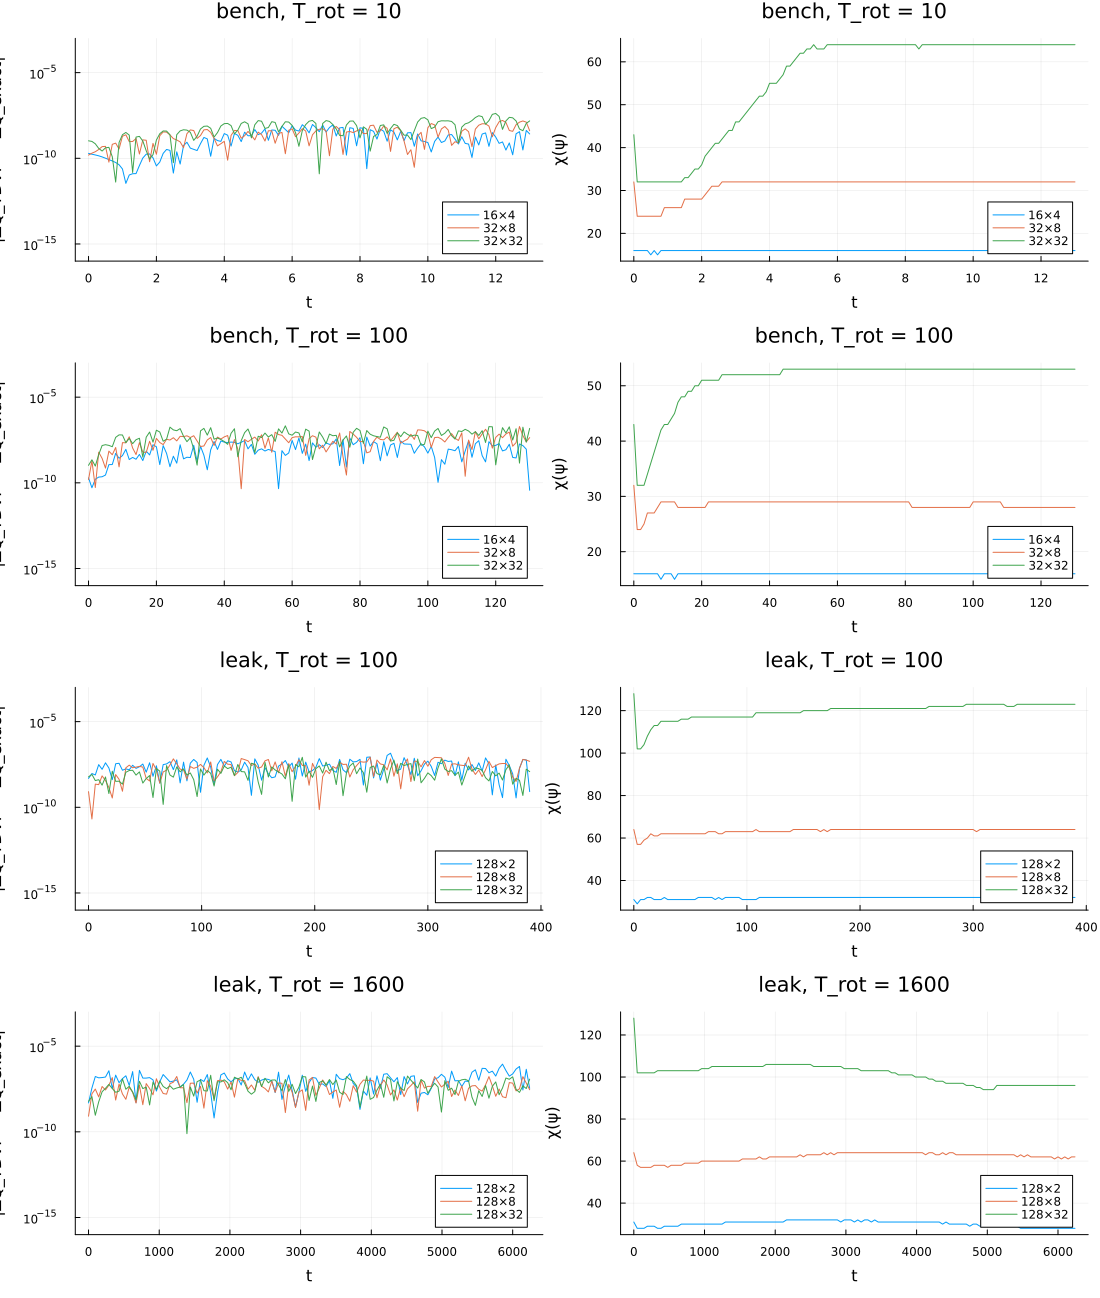

In [ ]:
using Plots
D = readdlm("td_tn_dQ.csv", ','; header = true)[1]
plots = []
for pt in ("bench", "leak"), rot in ROTS[pt]
    p = plot(; yscale = :log10, xlabel = "t", ylabel = "|ΔQ_TDVP − ΔQ_exact|", title = "$pt, T_rot = $(round(Int, rot))",
             legend = :bottomright, ylims = (1e-16, 1e-3))
    q = plot(; xlabel = "t", ylabel = "χ(ψ)", title = "$pt, T_rot = $(round(Int, rot))", legend = :bottomright)
    for (Lx, Ly) in SIZES[pt]
        sel = [D[i, 1] == pt && D[i, 2] == Lx && D[i, 3] == Ly && D[i, 4] == rot && (D[i, 5], D[i, 6]) == MAIN for i in axes(D, 1)]
        any(sel) || continue
        plot!(p, D[sel, 7], max.(abs.(D[sel, 8] .- D[sel, 9]), 1e-16); label = "$(2^Lx)×$(2^Ly)")
        plot!(q, D[sel, 7], D[sel, 10]; label = "$(2^Lx)×$(2^Ly)")
    end
    push!(plots, p, q)
end
plot(plots...; layout = (4, 2), size = (1100, 1300))

## 5. TDVP on large substrates

The scaling scan of the ramp, TN side: the benchmark point on $256^2$ to $2048^2$ sites at both speeds (and $4096^2$ on the fast ramp), and the leaking point on $256^2$ and
$512^2$ at $T_{\rm rot} = 100$. The sparse-reference runs of the same cases are in `msh_substrate_td_python.ipynb`, section 7 ($256^2$ to $1024^2$, and
the cost of one step at $2048^2$).

`run_large` is `run_case` without the dense comparison during the run. After the ramp it builds the final pair from the zero-mode
pipeline on $H(T)$ and computes the readouts of the Python notebook: $p_\pm$, the leak and the Majorana matrix $M$ (both pairs from
`mps_majoranas`, the convention of `majorana_matrix` in `substrate_model.py`). Each run writes `data/td_tn_large_<case>.npz` (series and
summary) and `data/td_tn_large_<case>.jls` (final MPS and sites).

Here the MPS has $2L + 2 = 18$ to 24 sites, so it is no longer full rank, and both truncations act: the SVD `cutoff` and the cap
`maxdim` = $\chi_{\max}$. The runs (one process each, about 18 at a time on the machine):

- **Scaling, cutoff $10^{-14}$.** Benchmark point, $L = 8$ to 11, both speeds, and $L = 12$ on the fast ramp, $\chi_{\max} = 256$; leaking point,
  $L = 8, 9$, $\chi_{\max} = 64$ and 128. Leaking-point runs with $\chi_{\max} = 256$ and cutoff $10^{-14}$, and with 128 on $1024^2$, were stopped
  after 16 hours without a result, once section 6 had shown that the readouts do not need them.
- **Cutoff scan** (section 6). Benchmark point, $512^2$, $T_{\rm rot} = 100$, $\chi_{\max} = 512$, cutoff $10^{-6}$ to $10^{-12}$; leaking point, $256^2$,
  $T_{\rm rot} = 100$, $\chi_{\max} = 256$, the same cutoffs.

All runs were redone on 4–5 November 2026 with the fixed Hamiltonian MPO (section 5.2), except the leaking-point run with cutoff
$10^{-12}$ and $\chi_{\max} = 256$: it keeps its result from the old MPO (the leaking point is not affected by the fix; the other
leaking-point runs changed by less than 10 % in $1 - F$).

The runs took up to 16 hours each, so they were made outside the notebook (the same code with one worker, `RUN_LARGE = false` here only
collects). The collection contracts each final MPS to a dense vector and computes $1 - F = 1 - |\langle\psi_{\rm sparse}|\psi_{\rm TDVP}\rangle|^2$
where a sparse-reference state exists, on the workers, and keeps it in `td_tn_large.csv` (one row per run, committed); $\Delta Q(t)$ and $\chi(t)$ go
to `td_tn_large_series.csv`.

Note on $\chi$: the summary of a run records the largest bond dimension including the initial state, which is the DMRG state (43 at the
benchmark point, 211 to 214 at the leaking point). The tables below show both: $\chi_0$ of $\psi_f(0)$ and $\chi_{\rm run}$, the largest over
the TDVP snapshots ($t > 0$).

In [ ]:
@everywhere begin
    using Serialization
    "Majoranas (γ₁, γ₂) = ((ψ + Cψ)/√2, i(ψ − Cψ)/√2) of an MPS fermion mode (Cconj from substrate_model.jl)."
    mps_majoranas(ψ; cutoff=1e-14) = (c = Cconj(ψ); (+(ψ, c; cutoff) / sqrt(2), +(im * ψ, -im * c; cutoff) / sqrt(2)))

    """
        run_large(point, L, rot; maxdim, cutoff, progress, ℓ, prefix, hcut) -> summary vector

    As run_case on the L × L substrate (2^L × 2^L sites), without the dense comparison. After the ramp: the final pair from the
    zero-mode pipeline on H(T), its weights p± on ψ(T), the leak and the Majorana matrix M. Writes data/td_tn_large_<case>.npz
    (ts, dQ, chi, t_wall, summary) and data/td_tn_large_<case>.jls (final MPS and sites). `progress = true` prints t, χ and ΔQ at
    every snapshot. `ℓ` overrides the chain length of the point, `prefix` the start of the file names (section 7), and `hcut` the
    MPO cutoff of the Hamiltonians (default: that of `msh_substrate` for H(0), of `ramp_mpo` for H(t); section 5.2).
    Summary: T, χ₀, χ_max (initial state included), t_dmrg0, t_tdvp, s/step, E_f(0), ΔQ(0), ΔQ(T), t_dmrgT, E_f(T),
    gap(T), p₊, p₋, leak, det M, max|Im M|, ΔQ₊(T).
    """
    function run_large(point, L, rot; maxdim=256, cutoff=1e-14, progress=false, ℓ=POINTS[point].ℓ, prefix="td_tn_large_",
                       hcut=nothing)
        P = POINTS[point].P
        hk = isnothing(hcut) ? (;) : (; cutoff = hcut)                 # MPO cutoff of H(0) and H(t) (section 5.2)
        g = Substrate(L, L, ℓ)
        T = ramp_duration(ℓ, rot); n = round(Int, T / DT); every = snap_every(T, DT)
        H0, sites = msh_substrate(g, S_z; hk..., P...)
        t_dmrg0 = @elapsed (z = zero_mode_subspace(H0, sites; xq = xqubits(g)))
        r = fermion_from_subspace(H0, sites, z.ψs, g)
        ψ = r.ψf
        ts, dQ, χ, tw = [0.0], [ΔQ_mode(ψ)], [maxlinkdim(ψ)], [0.0]
        s = 0; t_start = time()
        t_tdvp = @elapsed while s < n
            k = min(every, n - s); t0 = s * DT
            ψ = last(TB.evolve_with_tdvp_timedep(t -> ramp_mpo(t0 + t, g, rot, sites; hk..., P...), ψ, k, DT; maxdim, cutoff,
                                                 tol=1e-12, krylovdim=30, reverse_step=true))
            s += k
            push!(ts, s * DT); push!(dQ, ΔQ_mode(ψ)); push!(χ, maxlinkdim(ψ)); push!(tw, time() - t_start)
            progress && (@printf("t = %7.1f / %.0f  χ = %3d  ΔQ = %+.6e  TDVP %6.0f s\n", s * DT, T, χ[end], dQ[end], tw[end]); flush(stdout))
        end
        HT = ramp_mpo(T, g, rot, sites; hk..., P...)
        t_dmrgT = @elapsed (zT = zero_mode_subspace(HT, sites; xq = xqubits(g)))
        rT = fermion_from_subspace(HT, sites, zT.ψs, g)
        pp, pm = abs2(inner(rT.ψf, ψ)), abs2(inner(Cconj(rT.ψf), ψ))
        M = [inner(a, b) for a in mps_majoranas(rT.ψf), b in mps_majoranas(ψ)]   # both pairs with the same convention (as in Python)
        name = prefix * case_name(point, L, L, rot, maxdim, cutoff)
        serialize(joinpath(DATA_DIR, name * ".jls"), (; ψ, sites))
        summary = Float64[T, χ[1], maximum(χ), t_dmrg0, t_tdvp, t_tdvp / n, r.E_f, dQ[1], dQ[end], t_dmrgT, rT.E_f, zT.E_gap,
                          pp, pm, 1 - pp - pm, real(det(M)), maximum(abs.(imag.(M))), ΔQ_mode(rT.ψf)]
        npzwrite(joinpath(DATA_DIR, name * ".npz"), Dict("ts" => ts, "dQ" => dQ, "chi" => Float64.(χ), "t_wall" => tw, "summary" => summary))
        return summary
    end

    "1 − |⟨ψ_sparse|ψ_TDVP⟩|² of a finished large run against the sparse final state of the Python notebook (NaN if there is none)."
    function large_infidelity(point, L, rot, name)
        kf = joinpath(DATA_DIR, "td_py_psi_$(point)_$(L)_$(L)_rot$(round(Int, rot)).npz")
        isfile(kf) || return NaN
        d = deserialize(joinpath(DATA_DIR, name * ".jls"))
        w = py_vector(d.ψ, d.sites, 4^L); k = npzread(kf)["psiT"]
        return 1 - abs2(dot(k, w)) / (sum(abs2, k) * sum(abs2, w))
    end
end

RUN_LARGE = false
LARGE_JOBS = vcat([("bench", L, rot, 256, 1e-14) for L in 8:11 for rot in (10.0, 100.0)], [("bench", 12, 10.0, 256, 1e-14)],
                  [("leak", L, 100.0, m, 1e-14) for L in (8, 9) for m in (64, 128)],
                  [("bench", 9, 100.0, 512, c) for c in (1e-6, 1e-8, 1e-10, 1e-12)],
                  [("leak", 8, 100.0, 256, c) for c in (1e-6, 1e-8, 1e-10, 1e-12)])
large_name(j) = "td_tn_large_" * case_name(j[1], j[2], j[2], j[3], j[4], j[5])
large_npz(j) = joinpath(DATA_DIR, large_name(j) * ".npz")
todo = filter(j -> !isfile(large_npz(j)), LARGE_JOBS)
println(length(LARGE_JOBS), " cases, ", length(todo), " not run: ", join(large_name.(todo), ", "))
if RUN_LARGE && !isempty(todo)
    pmap(j -> run_large(j[1], j[2], j[3]; maxdim = j[4], cutoff = j[5]), todo)
end

# collect: summary row per run (1 − F computed once and kept in td_tn_large.csv), ΔQ(t) and χ(t) per run
large_file = "td_tn_large.csv"
large_cols = ["point", "L", "rot_T", "maxdim", "cutoff", "T", "chi0", "chi_run", "t_tdvp", "s_per_step", "dQ_T", "p_plus", "p_minus",
              "leak", "detM", "maxImM", "infT"]
old_inf = Dict{String, Float64}()
if isfile(large_file)
    A = readdlm(large_file, ','; header = true)[1]
    for r in eachrow(A)
        old_inf[large_name((String(r[1]), Int(r[2]), Float64(r[3]), Int(r[4]), Float64(r[5])))] = Float64(r[end])
    end
end
done_jobs = filter(j -> isfile(large_npz(j)), LARGE_JOBS)
need = filter(j -> !haskey(old_inf, large_name(j)), done_jobs)
need_names = large_name.(need)                       # names on the master (large_name is not defined on the workers)
for (j, x) in zip(need, pmap((j, nm) -> large_infidelity(j[1], j[2], j[3], nm), need, need_names))
    old_inf[large_name(j)] = x
end
open(large_file, "w") do io
    println(io, join(large_cols, ","))
    for j in done_jobs
        d = npzread(large_npz(j)); s = d["summary"]
        println(io, join(Any[j..., s[1], Int(s[2]), Int(maximum(d["chi"][2:end])), s[5], s[6], s[9], s[13], s[14], s[15], s[16], s[17],
                             old_inf[large_name(j)]], ","))
    end
end
open("td_tn_large_series.csv", "w") do io
    println(io, "point,L,rot_T,maxdim,cutoff,t,dQ,chi")
    for j in done_jobs
        d = npzread(large_npz(j))
        for k in eachindex(d["ts"]); println(io, join(Any[j..., d["ts"][k], d["dQ"][k], Int(d["chi"][k])], ",")); end
    end
end
println(length(done_jobs), " runs collected, 1 − F computed for ", length(need))

21 cases, 

0 not run: 


21 runs collected, 1 − F computed for 

20


### 5.1 Cost and accuracy against the sparse reference

Cutoff $10^{-14}$. Columns: $\chi_0$ and $\chi_{\rm run}$ (see above), the TDVP time per step and the sparse time per step of the Python
notebook (one run per process, with up to about 18 runs sharing the machine), the leak and $\det M$ of both methods, and the infidelity of
the final state. The sparse cost at $2048^2$ is the measured step time of `td_py_step2048.csv`. These times were measured with up to about 18 runs
sharing the machine; section 6.1 compares both methods on the idle machine.

In [ ]:
L_ = readdlm(large_file, ','; header = true); LG = L_[1]; lcol = Dict(c => i for (i, c) in enumerate(vec(L_[2])))
lv(r, c) = r[lcol[c]]
K_ = readdlm("td_py_large.csv", ','; header = true); KG = K_[1]; kc = Dict(c => i for (i, c) in enumerate(vec(K_[2])))
S_ = readdlm("td_py_step2048.csv", ','; header = true); SG = S_[1]; sc = Dict(c => i for (i, c) in enumerate(vec(S_[2])))
"Sparse-reference row of the Python notebook for (point, L, rot): (s per step, leak, det M); 2048² from the step timing (no readouts)."
function sparse_large(pt, L, rot)
    i = findfirst(r -> r[kc["point"]] == pt && r[kc["Lx"]] == L && r[kc["rot_T"]] == rot, collect(eachrow(KG)))
    i !== nothing && return (KG[i, kc["ms_per_step"]] / 1e3, KG[i, kc["leak"]], KG[i, kc["detM"]])
    i = findfirst(r -> r[sc["point"]] == pt && r[sc["L"]] == L, collect(eachrow(SG)))
    return i === nothing ? (NaN, NaN, NaN) : (SG[i, sc["ms_step"]] / 1e3, NaN, NaN)
end
@printf("%6s %11s %6s %5s | %4s %6s | %10s %10s %7s | %10s %10s | %8s %8s | %9s\n", "point", "substrate", "T_rot", "χmax", "χ₀", "χ_run",
        "TDVP/step", "sparse", "ratio", "leak", "sparse", "det M", "sparse", "1 − F")
for r in sort(collect(eachrow(LG)); by = r -> (lv(r, "point"), lv(r, "maxdim"), lv(r, "rot_T"), lv(r, "L")))
    lv(r, "cutoff") == 1e-14 || continue
    pt, L, rot = lv(r, "point"), Int(lv(r, "L")), lv(r, "rot_T")
    ks, kl, kd = sparse_large(pt, L, rot)
    @printf("%6s %5d×%-5d %6.0f %5d | %4d %6d | %9.2fs %9.2fs %7.2f | %10.3e %10.3e | %+8.4f %+8.4f | %9.1e\n", pt, 2^L, 2^L, rot,
            lv(r, "maxdim"), lv(r, "chi0"), lv(r, "chi_run"), lv(r, "s_per_step"), ks, lv(r, "s_per_step") / ks, lv(r, "leak"), kl,
            lv(r, "detM"), kd, lv(r, "infT"))
end

 point   substrate  T_rot  χmax |   χ₀  χ_run |  TDVP/step     sparse   ratio |       leak     sparse |    det M   sparse |     1 − F
 bench   256×256       10   256 |   43    125 |      1.31s      0.58s    2.26 |  5.317e-01  5.317e-01 |  -0.4683  -0.4683 |   2.5e-07


 bench   512×512       10   256 |   43     74 |      1.23s      2.62s    0.47 |  5.317e-01  5.317e-01 |  -0.4683  -0.4683 |   3.7e-07
 bench  1024×1024      10   256 |   43     74 |      1.18s     10.29s    0.12 |  5.317e-01  5.317e-01 |  -0.4683  -0.4683 |   4.4e-07
 bench  2048×2048      10   256 |   43     78 |      1.70s     22.19s    0.08 |  5.317e-01        NaN |  -0.4683     +NaN |       NaN
 bench  4096×4096      10   256 |   43     74 |      1.20s       NaNs     NaN |  5.317e-01        NaN |  -0.4683     +NaN |       NaN
 bench   256×256      100   256 |   43     52 |      0.76s      0.48s    1.59 |  4.725e-07  4.728e-07 |  -1.0000  -1.0000 |   1.8e-10
 bench   512×512      100   256 |   43     52 |      0.85s      2.14s    0.40 |  4.724e-07  4.728e-07 |  -1.0000  -1.0000 |   2.2e-10
 bench  1024×1024     100   256 |   43     48 |      0.91s     11.40s    0.08 |  4.705e-07  4.728e-07 |  -1.0000  -1.0000 |   4.4e-10
 bench  2048×2048     100   256 |   43    100 |      1.62s    

### 5.2 The Hamiltonian MPO cutoff

`msh_substrate` sums the terms of $H$ with a *relative* truncation `cutoff`. The norm of $H$ grows with the lattice, so a fixed relative
cutoff gives an absolute error in $H$ that grows with $N$. The runs of this notebook were first made with the old default $10^{-13}$
($\chi(H) = 7$–9 where the exact sum needs about 32): the error in $H\psi$ grew from $3\times10^{-12}$ at $256^2$ to $\sim10^{-6}$ at
$2048^2$, and with it the $\Delta Q$ error of the fast ramp ($1.8\times10^{-5}$ at $512^2$, $4.5\times10^{-5}$ at $1024^2$), while on the slow ramp
TDVP integrated the noise into the state, which grew to the cap of 256. Since 4 November 2026 `ramp_mpo` uses $10^{-16}$ (and
`msh_substrate` $10^{-20}$ for the static Hamiltonian, see `msh_substrate_tn.ipynb`, section 9), and every run of this notebook was redone.

The comparison: the benchmark runs of section 5 with the MPO cutoff (`hcut`) $10^{-13}$, $10^{-16}$ (the runs of section 5) and $10^{-20}$
(fast ramp only). The sparse $\Delta Q(t)$ and readouts are the same at every size to $10^{-12}$, so those of $256^2$ serve as the reference
also at $2048^2$ and $4096^2$. The $10^{-13}$ files were saved before the rerun (`data/mpo_cut/`); `RUN_MPO = false` only collects, into
`td_tn_mpo_cutoff.csv`.

In [ ]:
RUN_MPO = false
MPO_JOBS = vcat([(1e-13, L, rot) for L in 8:11 for rot in (10.0, 100.0)], [(1e-20, L, 10.0) for L in 9:12])
mpo_name(h, L, rot) = "mpo_cut/hc$(h)_" * large_name(("bench", L, rot, 256, 1e-14))
if RUN_MPO
    todo_m = filter(j -> !isfile(joinpath(DATA_DIR, mpo_name(j...) * ".npz")), MPO_JOBS)
    pmap(j -> run_large("bench", j[2], j[3]; hcut = j[1], prefix = "mpo_cut/hc$(j[1])_td_tn_large_"), todo_m)
end
refs = Dict(rot => npzread(joinpath(DATA_DIR, "td_py_psi_bench_8_8_rot$(round(Int, rot)).npz")) for rot in (10.0, 100.0))
pref = Dict(rot => sparse_large("bench", 8, rot) for rot in (10.0, 100.0))              # (s/step, leak, det M)
open("td_tn_mpo_cutoff.csv", "w") do io
    println(io, "hcut,L,rot_T,chi_max,max_ddQ,ddQ_T,ddetM,leak")
    for h in (1e-13, 1e-16, 1e-20), L in 8:12, rot in (10.0, 100.0)
        f = h == 1e-16 ? large_npz(("bench", L, rot, 256, 1e-14)) : joinpath(DATA_DIR, mpo_name(h, L, rot) * ".npz")
        isfile(f) || continue
        d = npzread(f); s = d["summary"]; dq = abs.(d["dQ"] .- refs[rot]["dQ"])
        println(io, join(Any[h, L, rot, Int(maximum(d["chi"][2:end])), maximum(dq), dq[end], abs(s[16] - pref[rot][3]), s[15]], ","))
    end
end
MC = readdlm("td_tn_mpo_cutoff.csv", ','; header = true)[1]
@printf("%6s %11s %6s | %5s | %12s %12s %12s\n", "T_rot", "substrate", "hcut", "χ_run", "max|ΔQ err|", "ΔQ(T) err", "|Δ det M|")
for r in sort(collect(eachrow(MC)); by = r -> (r[3], r[2], -r[1]))
    @printf("%6.0f %5d×%-5d %6.0e | %5d | %12.2e %12.2e %12.2e\n", r[3], 2^r[2], 2^r[2], r[1], r[4], r[5], r[6], r[7])
end

 T_rot   substrate   hcut | χ_run |  max|ΔQ err|    ΔQ(T) err    |Δ det M|
    10   256×256    1e-13 |   126 |     1.33e-05     9.75e-06     9.95e-07


    10   256×256    1e-16 |   125 |     3.43e-06     8.82e-07     7.16e-08
    10   512×512    1e-13 |    74 |     1.88e-05     1.76e-05     3.03e-06
    10   512×512    1e-16 |    74 |     3.45e-06     1.64e-06     1.09e-07
    10   512×512    1e-20 |    74 |     3.46e-06     1.52e-06     1.12e-07
    10  1024×1024   1e-13 |    74 |     5.12e-05     4.49e-05     1.58e-05
    10  1024×1024   1e-16 |    74 |     3.45e-06     2.03e-06     7.62e-08
    10  1024×1024   1e-20 |    74 |     3.38e-06     1.62e-06     1.85e-08
    10  2048×2048   1e-13 |    76 |     1.23e-04     1.17e-04     3.19e-05
    10  2048×2048   1e-16 |    78 |     3.51e-06     2.30e-06     2.48e-08
    10  2048×2048   1e-20 |    74 |     3.47e-06     2.30e-06     1.26e-07
    10  4096×4096   1e-16 |    74 |     1.28e-05     5.83e-06     3.49e-07
    10  4096×4096   1e-20 |    74 |     1.26e-05     7.06e-06     6.13e-07
   100   256×256    1e-13 |   256 |     3.37e-05     3.37e-05     2.20e-08
   100   256×256    1e-16

## 6. Cutoff and bond-dimension cap on large substrates

Which truncation the readouts need, where the MPS is not full rank: the cutoff scan of section 5 and the leaking-point runs with
$\chi_{\max} = 64$ and 128, against the same sparse-reference states. Left: $\chi(t)$ of the benchmark scan; middle: of the leaking-point runs; right:
the time per step against the substrate size for TDVP (cutoff $10^{-14}$, and $10^{-12}$ where run) and the sparse reference.

In [ ]:
@printf("%6s %9s | %5s %8s | %4s %6s | %10s | %10s %10s | %8s | %9s\n", "point", "substrate", "χmax", "cutoff", "χ₀", "χ_run",
        "TDVP/step", "leak", "sparse", "det M", "1 − F")
for (pt, L) in (("bench", 9), ("leak", 8))
    ks, kl, kd = sparse_large(pt, L, 100.0)
    for r in sort(collect(eachrow(LG)); by = r -> (-lv(r, "cutoff"), lv(r, "maxdim")))
        (lv(r, "point"), lv(r, "L"), lv(r, "rot_T")) == (pt, L, 100.0) || continue
        @printf("%6s %4d×%-4d | %5d %8.0e | %4d %6d | %9.2fs | %10.3e %10.3e | %+8.4f | %9.1e\n", pt, 2^L, 2^L, lv(r, "maxdim"),
                lv(r, "cutoff"), lv(r, "chi0"), lv(r, "chi_run"), lv(r, "s_per_step"), lv(r, "leak"), kl, lv(r, "detM"), lv(r, "infT"))
    end
    @printf("%6s %4d×%-4d | %16s | %11s | %9.2fs | %10s %10.3e | %+8.4f |\n", pt, 2^L, 2^L, "sparse", "", ks, "", kl, kd)
end

 point substrate |  χmax   cutoff |   χ₀  χ_run |  TDVP/step |       leak     sparse |    det M |     1 − F
 bench  512×512  |   512    1e-06 |   43     31 |      0.38s |  4.444e-03  4.728e-07 |  -0.9956 |   4.5e-03


 bench  512×512  |   512    1e-08 |   43     63 |      0.61s |  3.380e-04  4.728e-07 |  -0.9997 |   3.4e-04
 bench  512×512  |   512    1e-10 |   43     32 |      0.69s |  9.330e-07  4.728e-07 |  -1.0000 |   4.5e-07
 bench  512×512  |   512    1e-12 |   43     31 |      0.60s |  4.751e-07  4.728e-07 |  -1.0000 |   2.8e-09
 bench  512×512  |   256    1e-14 |   43     52 |      0.85s |  4.724e-07  4.728e-07 |  -1.0000 |   2.2e-10
 bench  512×512  |           sparse |             |      2.14s |             4.728e-07 |  -1.0000 |
  leak  256×256  |   256    1e-06 |  213    116 |      2.76s |  9.068e-01  9.082e-01 |  -0.0932 |   2.2e-03


  leak  256×256  |   256    1e-08 |  213    117 |      3.79s |  9.083e-01  9.082e-01 |  -0.0917 |   3.5e-05
  leak  256×256  |   256    1e-10 |  213    146 |      5.53s |  9.082e-01  9.082e-01 |  -0.0918 |   1.8e-06
  leak  256×256  |   256    1e-12 |  214    256 |      8.69s |  9.082e-01  9.082e-01 |  -0.0918 |   9.5e-07
  leak  256×256  |    64    1e-14 |  213     64 |      3.38s |  9.077e-01  9.082e-01 |  -0.0923 |   2.2e-03
  leak  256×256  |   128    1e-14 |  213    128 |      8.37s |  9.082e-01  9.082e-01 |  -0.0918 |   1.2e-06
  leak  256×256  |           sparse |             |      0.45s |             9.082e-01 |  -0.0918 |


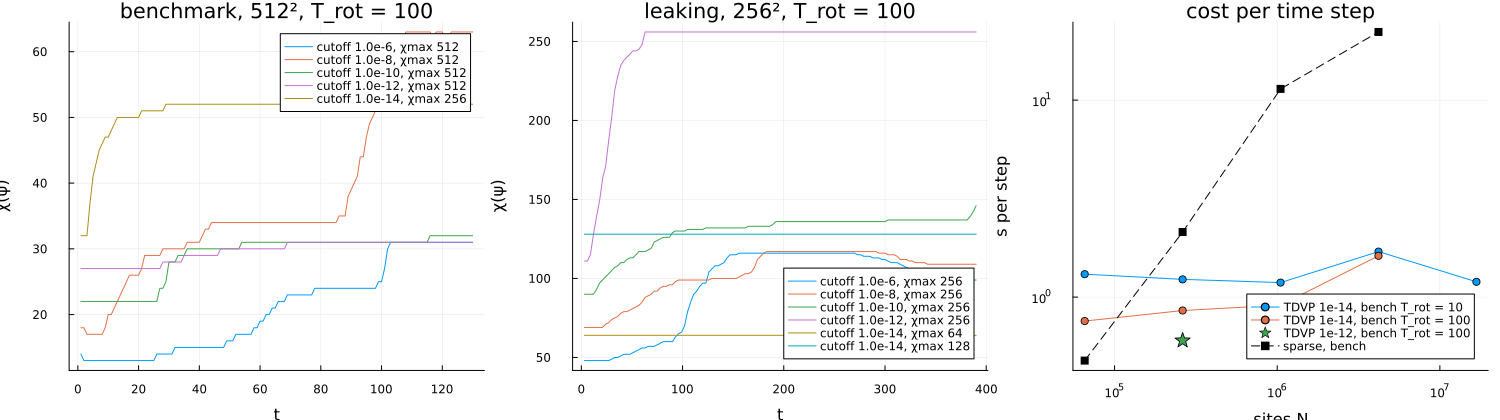

In [ ]:
using Plots
SR = readdlm("td_tn_large_series.csv", ','; header = true)[1]
series(pt, L, rot, m, c) = (sel = [SR[i, 1] == pt && SR[i, 2] == L && SR[i, 3] == rot && SR[i, 4] == m && SR[i, 5] == c for i in axes(SR, 1)];
                            (SR[sel, 6], SR[sel, 8]))
p1 = plot(; xlabel = "t", ylabel = "χ(ψ)", title = "benchmark, 512², T_rot = 100", legend = :topright)
for (m, c) in ((512, 1e-6), (512, 1e-8), (512, 1e-10), (512, 1e-12), (256, 1e-14))
    t, χ = series("bench", 9, 100.0, m, c); isempty(t) || plot!(p1, t[2:end], χ[2:end]; label = "cutoff $c, χmax $m")
end
p2 = plot(; xlabel = "t", ylabel = "χ(ψ)", title = "leaking, 256², T_rot = 100", legend = :bottomright)
for (m, c) in ((256, 1e-6), (256, 1e-8), (256, 1e-10), (256, 1e-12), (64, 1e-14), (128, 1e-14))
    t, χ = series("leak", 8, 100.0, m, c); isempty(t) || plot!(p2, t[2:end], χ[2:end]; label = "cutoff $c, χmax $m")
end
p3 = plot(; xscale = :log10, yscale = :log10, xlabel = "sites N", ylabel = "s per step", title = "cost per time step", legend = :bottomright)
for rot in (10.0, 100.0)
    rs = sort(filter(r -> lv(r, "point") == "bench" && lv(r, "rot_T") == rot && lv(r, "cutoff") == 1e-14, collect(eachrow(LG))); by = r -> lv(r, "L"))
    plot!(p3, [4.0^lv(r, "L") for r in rs], [lv(r, "s_per_step") for r in rs]; marker = :circle, label = "TDVP 1e-14, bench T_rot = $(round(Int, rot))")
end
r12 = filter(r -> lv(r, "point") == "bench" && lv(r, "cutoff") == 1e-12, collect(eachrow(LG)))
isempty(r12) || scatter!(p3, [4.0^lv(r, "L") for r in r12], [lv(r, "s_per_step") for r in r12]; marker = :star5, ms = 8,
                         label = "TDVP 1e-12, bench T_rot = 100")
Lk = 8:11
plot!(p3, 4.0 .^ Lk, [sparse_large("bench", L, 100.0)[1] for L in Lk]; marker = :square, ls = :dash, color = :black, label = "sparse, bench")
plot(p1, p2, p3; layout = (1, 3), size = (1500, 420), left_margin = 5Plots.mm, bottom_margin = 5Plots.mm)

### 6.1 Step times on the idle machine

The times per step of sections 5 and 6 were measured with up to about 18 runs sharing the machine, which slowed TDVP 1.6–4.2 times and
the sparse reference 2.3–4.7 times, not by the same factor. Here both are timed with nothing else running: one TDVP step (with the $H(t)$ rebuild) at
mid-ramp from the final state of each run, the median of 3 after a first one, and the sparse step of `msh_substrate_td_python.ipynb`,
section 7.1. The TDVP time depends on the bond dimension of the state, so it is that of the final state ($\chi_{\rm state}$). The
leaking-point run with cutoff $10^{-12}$ and $\chi_{\max} = 256$ is left out: its state is from the old MPO (section 5); with the current
`ramp_mpo` its step takes 29 s (measured on the GPU workstation's CPU, `gpu_bench/results/`). Results to `td_tn_step_idle.csv` (`RUN_IDLE = false` only loads).

In [ ]:
RUN_IDLE = false
idle_file = "td_tn_step_idle.csv"
if RUN_IDLE || !isfile(idle_file)
    open(idle_file, "w") do io
        println(io, "point,L,rot_T,maxdim,cutoff,chi_state,s_per_step")
        for j in filter(j -> isfile(large_npz(j)), LARGE_JOBS)
            pt, L, rot, maxdim, cutoff = j; P, ℓ = POINTS[pt]; g = Substrate(L, L, ℓ)
            d = deserialize(joinpath(DATA_DIR, large_name(j) * ".jls")); tm = 0.5 * ramp_duration(ℓ, rot)
            step() = TB.evolve_with_tdvp_timedep(t -> ramp_mpo(tm + t, g, rot, d.sites; P...), d.ψ, 1, DT; maxdim, cutoff, tol=1e-12,
                                                 krylovdim=30, reverse_step=true)
            step(); ts = sort([@elapsed(step()) for _ in 1:3])
            println(io, join(Any[pt, L, rot, maxdim, cutoff, maxlinkdim(d.ψ), ts[2]], ","))
        end
    end
end
I_ = readdlm(idle_file, ','; header = true); IG = I_[1]; ic = Dict(c => i for (i, c) in enumerate(vec(I_[2])))
Q_ = readdlm("td_py_step_idle.csv", ','; header = true); QG = Q_[1]; qc = Dict(c => i for (i, c) in enumerate(vec(Q_[2])))
"Idle sparse s/step; the step cost does not depend on T_rot (0.178 s at 256² for both), so a missing speed takes the other one."
function sparse_idle(pt, L, rot)
    i = findfirst(r -> r[qc["point"]] == pt && r[qc["L"]] == L && r[qc["rot_T"]] == rot, collect(eachrow(QG)))
    i === nothing && (i = findfirst(r -> r[qc["point"]] == pt && r[qc["L"]] == L, collect(eachrow(QG))))
    return i === nothing ? NaN : QG[i, qc["s_per_step"]]
end
shared_tdvp(pt, L, rot, m, c) = (i = findfirst(r -> (lv(r, "point"), lv(r, "L"), lv(r, "rot_T"), lv(r, "maxdim"), lv(r, "cutoff")) == (pt, L, rot, m, c),
                                               collect(eachrow(LG))); i === nothing ? NaN : lv(LG[i, :], "s_per_step"))
@printf("%6s %11s %6s %5s %8s | %7s | %10s %10s | %10s %10s | %14s\n", "point", "substrate", "T_rot", "χmax", "cutoff", "χ_state",
        "TDVP idle", "(shared)", "sparse idle", "(shared)", "TDVP / sparse")
for r in sort(collect(eachrow(IG)); by = r -> (r[ic["point"]], r[ic["rot_T"]], -r[ic["cutoff"]], r[ic["maxdim"]], r[ic["L"]]))
    pt, L, rot, m, c = r[ic["point"]], Int(r[ic["L"]]), Float64(r[ic["rot_T"]]), Int(r[ic["maxdim"]]), Float64(r[ic["cutoff"]])
    ti, ki = r[ic["s_per_step"]], sparse_idle(pt, L, rot)
    @printf("%6s %5d×%-5d %6.0f %5d %8.0e | %7d | %9.2fs %9.2fs | %9.2fs %9.2fs | %14.2f\n", pt, 2^L, 2^L, rot, m, c, r[ic["chi_state"]],
            ti, shared_tdvp(pt, L, rot, m, c), ki, sparse_large(pt, L, rot)[1], ti / ki)
end

 point   substrate  T_rot  χmax   cutoff | χ_state |  TDVP idle   (shared) | sparse idle   (shared) |  TDVP / sparse
 bench   256×256       10   256    1e-14 |     125 |      3.35s      1.31s |      0.18s      0.58s |          18.80


 bench   512×512       10   256    1e-14 |      74 |      0.86s      1.23s |      0.77s      2.62s |           1.11
 bench  1024×1024      10   256    1e-14 |      74 |      0.76s      1.18s |      3.66s     10.29s |           0.21
 bench  2048×2048      10   256    1e-14 |      75 |      1.32s      1.70s |     14.97s     22.19s |           0.09
 bench  4096×4096      10   256    1e-14 |      74 |      0.88s      1.20s |       NaNs       NaNs |            NaN
 bench   512×512      100   512    1e-06 |      31 |      0.28s      0.38s |      0.78s      2.14s |           0.36
 bench   512×512      100   512    1e-08 |      63 |      0.69s      0.61s |      0.78s      2.14s |           0.88
 bench   512×512      100   512    1e-10 |      32 |      0.32s      0.69s |      0.78s      2.14s |           0.42
 bench   512×512      100   512    1e-12 |      31 |      0.39s      0.60s |      0.78s      2.14s |           0.50
 bench   256×256      100   256    1e-14 |      51 |      0.58s      0.7

## 7. Chain length

How the bond dimension of the ramp grows with the chain: the fast benchmark ramp ($T_{\rm rot} = 10$) on $512^2$ for $\ell = 8$, 12, 16,
24, 48 and 96 ($\chi_{\max} = 256$, cutoff $10^{-14}$; the ramp lasts $T = (((\ell - 4)/2 - 1)\,0.1 + 1)\,T_{\rm rot}$, 11 to 55). There is no
sparse reference for $\ell \ne 12$; the readouts are those of `run_large`. $\ell = 12$ is the run of section 5. The runs shared the machine,
so the times per step are only indicative. Results in `data/ell_scan/td_ell<ℓ>_*.npz` and `ell_scan_td.csv` (`RUN_ELL = false` only
collects); the static zero modes against $\ell$ are in `msh_substrate_tn.ipynb`, section 10.

In [ ]:
RUN_ELL = false
ELL_TD = [8, 16, 24, 48, 96]
ell_name(ℓ) = "ell_scan/td_ell$(ℓ)_" * case_name("bench", 9, 9, 10.0, 256, 1e-14)
if RUN_ELL
    pmap(ℓ -> run_large("bench", 9, 10.0; ℓ, prefix = "ell_scan/td_ell$(ℓ)_"), filter(ℓ -> !isfile(joinpath(DATA_DIR, ell_name(ℓ) * ".npz")), ELL_TD))
end
open("ell_scan_td.csv", "w") do io
    println(io, "point,L,ell,rot_T,maxdim,cutoff,T,chi0,chi_max,s_per_step,dQ_T,p_plus,p_minus,leak,detM")
    for ℓ in sort(vcat(ELL_TD, 12))
        f = ℓ == 12 ? large_npz(("bench", 9, 10.0, 256, 1e-14)) : joinpath(DATA_DIR, ell_name(ℓ) * ".npz")
        s = npzread(f)["summary"]
        println(io, join(Any["bench", 9, ℓ, 10.0, 256, 1e-14, s[1], Int(s[2]), Int(s[3]), s[6], s[9], s[13], s[14], s[15], s[16]], ","))
    end
end
EL = readdlm("ell_scan_td.csv", ','; header = true)[1]
@printf("%4s %6s | %4s %5s | %9s | %12s %10s %10s %9s\n", "ℓ", "T", "χ₀", "χmax", "s/step", "ΔQ(T)", "p₋", "leak", "det M")
for r in eachrow(EL)
    @printf("%4d %6.1f | %4d %5d | %8.2fs | %+12.4e %10.3e %10.3e %+9.5f\n", r[3], r[7], r[8], r[9], r[10], r[11], r[13], r[14], r[15])
end

   ℓ      T |   χ₀  χmax |    s/step |        ΔQ(T)         p₋       leak     det M
   8   11.0 |   40    64 |     1.52s |  +1.1192e-01  9.048e-01  9.520e-02  -0.90480


  12   13.0 |   43    74 |     1.23s |  +1.5998e-03  4.683e-01  5.317e-01  -0.46832
  16   15.0 |   45    85 |     2.34s |  -2.7820e-02  8.678e-16  7.870e-01  +0.21302
  24   19.0 |   44   104 |     2.47s |  -1.2948e-02  2.267e-02  9.773e-01  -0.02267
  48   31.0 |   44   256 |    12.27s |  +1.1999e-04  2.067e-05  1.000e+00  -0.00002
  96   55.0 |   46   256 |    22.89s |  -7.6175e-04  1.565e-14  1.000e+00  +0.00002


## 8. Summary

Times per step are those of the idle machine (section 6.1) unless marked "shared"; with up to 18 runs sharing the machine the times of
sections 5 and 6 are off by up to a factor 2, differently for the two methods. All results are with the fixed Hamiltonian MPO (section 5.2).

- **Exact where the MPS is full rank.** At the small sizes (sections 3 and 4) TDVP reproduces the exact evolution to $1 - F \le 6\times10^{-11}$
  and $|\Delta Q_{\rm TDVP} - \Delta Q_{\rm exact}| \le 9\times10^{-7}$ with cutoff $10^{-14}$ ($10^{-20}$: $9\times10^{-14}$; $10^{-12}$: $2.5\times10^{-9}$;
  $10^{-10}$: $3\times10^{-7}$). There it is 150–700 times slower per step than the sparse reference (shared).
- **The Hamiltonian MPO cutoff** (section 5.2). With the old relative cutoff $10^{-13}$ the error of $H(t)$ grew with the substrate, and with
  it the $\Delta Q$ error of the fast ramp (to $1.2\times10^{-4}$ at $2048^2$) and the bond dimension of the slow ramp (to the cap). With
  $10^{-16}$ the $\Delta Q(T)$ error is $1$–$2.3\times10^{-6}$ from $256^2$ to $2048^2$. At $4096^2$ an excess remains ($5.8\times10^{-6}$, $|\Delta p_-| =
  3.5\times10^{-7}$) whose cause is open; it is not the MPO, the TDVP truncation, the Krylov settings, the chain position or the initial state
  (findings report, section 4.1).
- **Fast benchmark ramp: TDVP wins from $1024^2$.** $\chi$ stays at 74–78 from $512^2$ to $4096^2$ (125 at $256^2$), so a TDVP step costs
  0.76–1.32 s, while a sparse step grows $\propto N$ (0.18 s to 15 s): TDVP is 19 times slower at $256^2$, level at $512^2$, 4.8 times
  faster at $1024^2$ and 11 times at $2048^2$. $1 - F = 2.5$–$4.4\times10^{-7}$, $|\Delta p_-| \le 1.1\times10^{-7}$ up to $2048^2$.
- **Slow benchmark ramp.** $\chi = 48$–52 up to $1024^2$ and 104 at $2048^2$ with cutoff $10^{-14}$; a step costs 0.58–0.66 s (1.3 s at
  $2048^2$): 3 times slower than the sparse reference at $256^2$, 1.2 times faster at $512^2$, 6 times at $1024^2$, 11 times at $2048^2$.
  $1 - F = 1.8$–$4.4\times10^{-10}$, $|\Delta p_-| \le 5\times10^{-9}$. The cutoff scan at $512^2$: $10^{-12}$ gives $1 - F = 2.8\times10^{-9}$ at
  0.39 s per step against 0.66 s for $10^{-14}$; $10^{-10}$ gives $4.5\times10^{-7}$ and twice the leak; $10^{-8}$ and $10^{-6}$ corrupt the state
  ($3\times10^{-4}$, $4\times10^{-3}$) and the leak. **The default cutoff is $10^{-14}$** (it had been $10^{-12}$ while the old MPO drove
  $10^{-14}$ to the cap), tightened for ramps much longer than these 1300–3900 steps.
- **Leaking point: the readouts need little bond dimension, but the sparse reference is faster up to $512^2$.** Most of the mode leaves the
  chain, and the readouts weigh only what remains in the final pair: with $\chi_{\max} = 64$ the leak (0.9077) and $\det M$ ($-0.0923$) are within
  $6\times10^{-4}$ of the sparse reference (0.9082, $-0.0918$) at $1 - F = 2\times10^{-3}$ to $10^{-2}$. $\chi_{\max} = 128$ gives $1 - F = 1.2\times10^{-6}$ on
  both $256^2$ and $512^2$, so the bond dimension the state needs does not grow with the substrate. The fixed MPO made a step about 1.9 times
  more expensive here ($\chi(H) \approx 30$ instead of 7–9): 2.1–2.4 s ($\chi_{\max} = 64$) and 8.8–9.5 s ($\chi_{\max} = 128$) against the sparse
  reference's 0.16 s ($256^2$) and 0.73 s ($512^2$), i.e. 2.9 and 12 times slower at $512^2$. With the TDVP step nearly independent of $N$ and
  the sparse step $\propto N$ (3.4 s at $1024^2$, 14 s at $2048^2$), the crossing should come near $1024^2$ for $\chi_{\max} = 64$ and near $2048^2$
  for $\chi_{\max} = 128$ (extrapolations). Cutoff $10^{-12}$ with $\chi_{\max} = 256$ reaches the cap and gives $1 - F = 9.5\times10^{-7}$, barely
  better than the cap of 128, at 3 times its cost: **leaky runs use a cap of about 128.**
- **Chain length** (section 7). On the fast ramp $\chi$ grows with $\ell$ (64 to 104 for $\ell = 8$ to 24, the cap of 256 at 48 and 96), because
  long chains are driven far from adiabatically (leak 0.1 to 1); the slow-ramp scan is still to be done.
- **Memory.** A TDVP run needs about 2 GB at every size (mostly the Julia runtime); the sparse reference needs the MUMPS factorization for the
  initial and final pair, 26.7 GB at $1024^2$ and an estimated 121 GB at $2048^2$, while the evolution alone takes 21 GB at $2048^2$.
- **Not covered.** The slow leaking ramp ($T_{\rm rot} = 1600$, 62 400 steps) at the large sizes.